## 18 Movement Efficiency and Stability (Flag 18)

### Dataset Overview
A constructed WorldTrace case with 243 trajectories. Geometry source: Observed map-matched NYC WorldTrace road paths or continuous road-aligned return traversals. Environmental, temporal, mode, vehicle, and event attributes are arranged to make all stated comparisons measurable without changing the route coordinates used by the figures.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Investigate variations in movement efficiency and stability across different travel conditions.

Role: Urban mobility analyst


Category: Peak period, vehicle size, speed stability, and detour exceptions

### Your Objective
Use the provided tables and visual results to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

Load the libraries used below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

Load the primary and supporting point tables.

In [ ]:
dataset_path='trajectories.csv'
df=pd.read_csv(dataset_path,low_memory=False)
df['departure_time']=pd.to_datetime(df.departure_time)
df['arrival_time']=pd.to_datetime(df.arrival_time)

In [ ]:
user_dataset_path='trajectory_points.csv'
user_df=pd.read_csv(user_dataset_path,low_memory=False)

### **Question 1**: Do peak-period trips have more variable travel times and speeds than off-peak trips?

#### Analysis action

Compare both travel-time and mean-speed distributions across ordinary trips; keep the three separately flagged route-detour exceptions for Question 3.

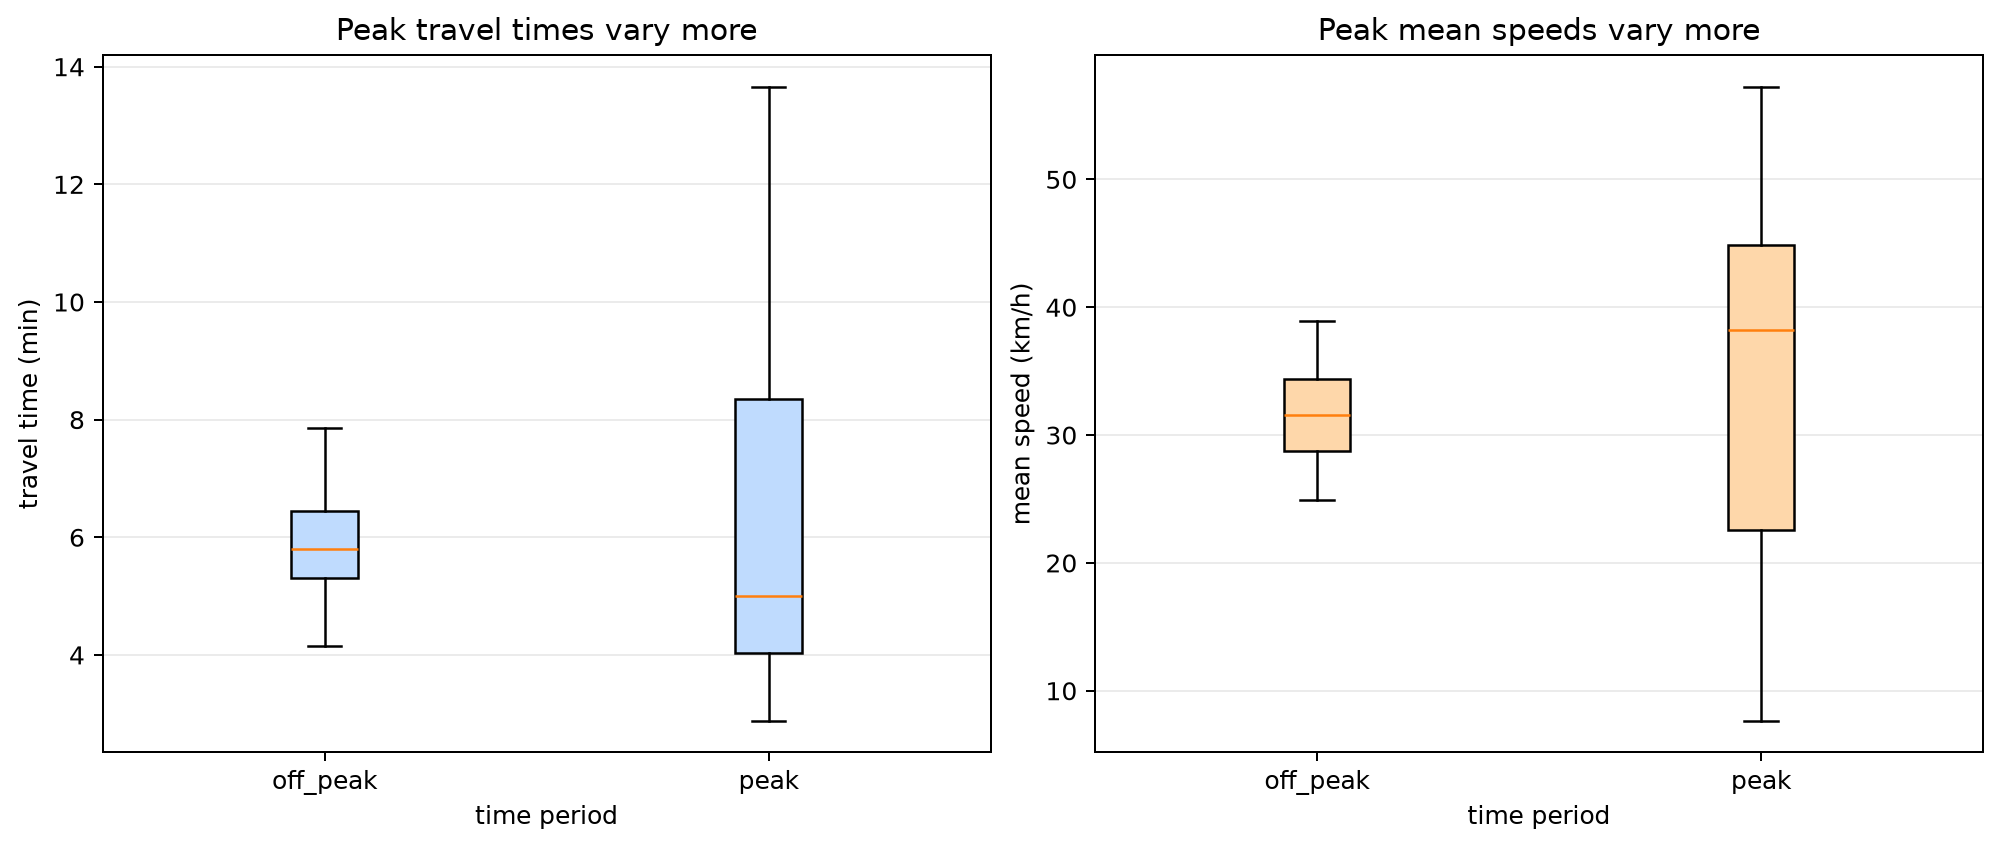

In [ ]:
ordinary=df[~df.is_directness_exception];g=ordinary.groupby('time_period').agg(time_mean=('travel_time_min','mean'),time_sd=('travel_time_min','std'),speed_mean=('mean_speed_kmh','mean'),speed_sd=('mean_speed_kmh','std'),within_speed_sd=('within_trip_speed_sd_kmh','mean'));print(g.round(2))
fig,ax=plt.subplots(1,2,figsize=(11,4.6),constrained_layout=True);order=['off_peak','peak']
ax[0].boxplot([ordinary.loc[ordinary.time_period.eq(k),'travel_time_min'] for k in order],tick_labels=order,showfliers=False,patch_artist=True,boxprops={'facecolor':'#bfdbfe'});ax[0].set(title='Peak travel times vary more',xlabel='time period',ylabel='travel time (min)');ax[0].grid(axis='y',alpha=.25)
ax[1].boxplot([ordinary.loc[ordinary.time_period.eq(k),'mean_speed_kmh'] for k in order],tick_labels=order,showfliers=False,patch_artist=True,boxprops={'facecolor':'#fed7aa'});ax[1].set(title='Peak mean speeds vary more',xlabel='time period',ylabel='mean speed (km/h)');ax[1].grid(axis='y',alpha=.25);plt.show()
# Display the synchronized figure.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex18_insight_1",
  "insight": "Trips during peak periods show greater variation in travel time and speed than trips during off-peak periods.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_1.png"
    ],
    "title": "Movement Efficiency and Stability: Insight 1",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "Do peak-period trips have more variable travel times and speeds than off-peak trips?",
  "actionable_insight": "Compare both travel-time and mean-speed distributions across ordinary trips; keep the three separately flagged route-detour exceptions for Question 3.",
  "code": "ordinary=df[~df.is_directness_exception];g=ordinary.groupby('time_period').agg(time_mean=('travel_time_min','mean'),time_sd=('travel_time_min','std'),speed_mean=('mean_speed_kmh','mean'),speed_sd=('mean_speed_kmh','std'),within_speed_sd=('within_trip_speed_sd_kmh','mean'));print(g.round(2))\nfig,ax=plt.subplots(1,2,figsize=(11,4.6),constrained_layout=True);order=['off_peak','peak']\nax[0].boxplot([ordinary.loc[ordinary.time_period.eq(k),'travel_time_min'] for k in order],tick_labels=order,showfliers=False,patch_artist=True,boxprops={'facecolor':'#bfdbfe'});ax[0].set(title='Peak travel times vary more',xlabel='time period',ylabel='travel time (min)');ax[0].grid(axis='y',alpha=.25)\nax[1].boxplot([ordinary.loc[ordinary.time_period.eq(k),'mean_speed_kmh'] for k in order],tick_labels=order,showfliers=False,patch_artist=True,boxprops={'facecolor':'#fed7aa'});ax[1].set(title='Peak mean speeds vary more',xlabel='time period',ylabel='mean speed (km/h)');ax[1].grid(axis='y',alpha=.25);plt.show()",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "matched_road_position",
    "trajectory_id"
  ]
}

### **Question 2**: For comparable route-distance bands, how do smaller and larger cars differ in speed and stability?

#### Analysis action

Show that small and large cars use the same route-distance mix, then compare mean speed and within-trip speed variability.

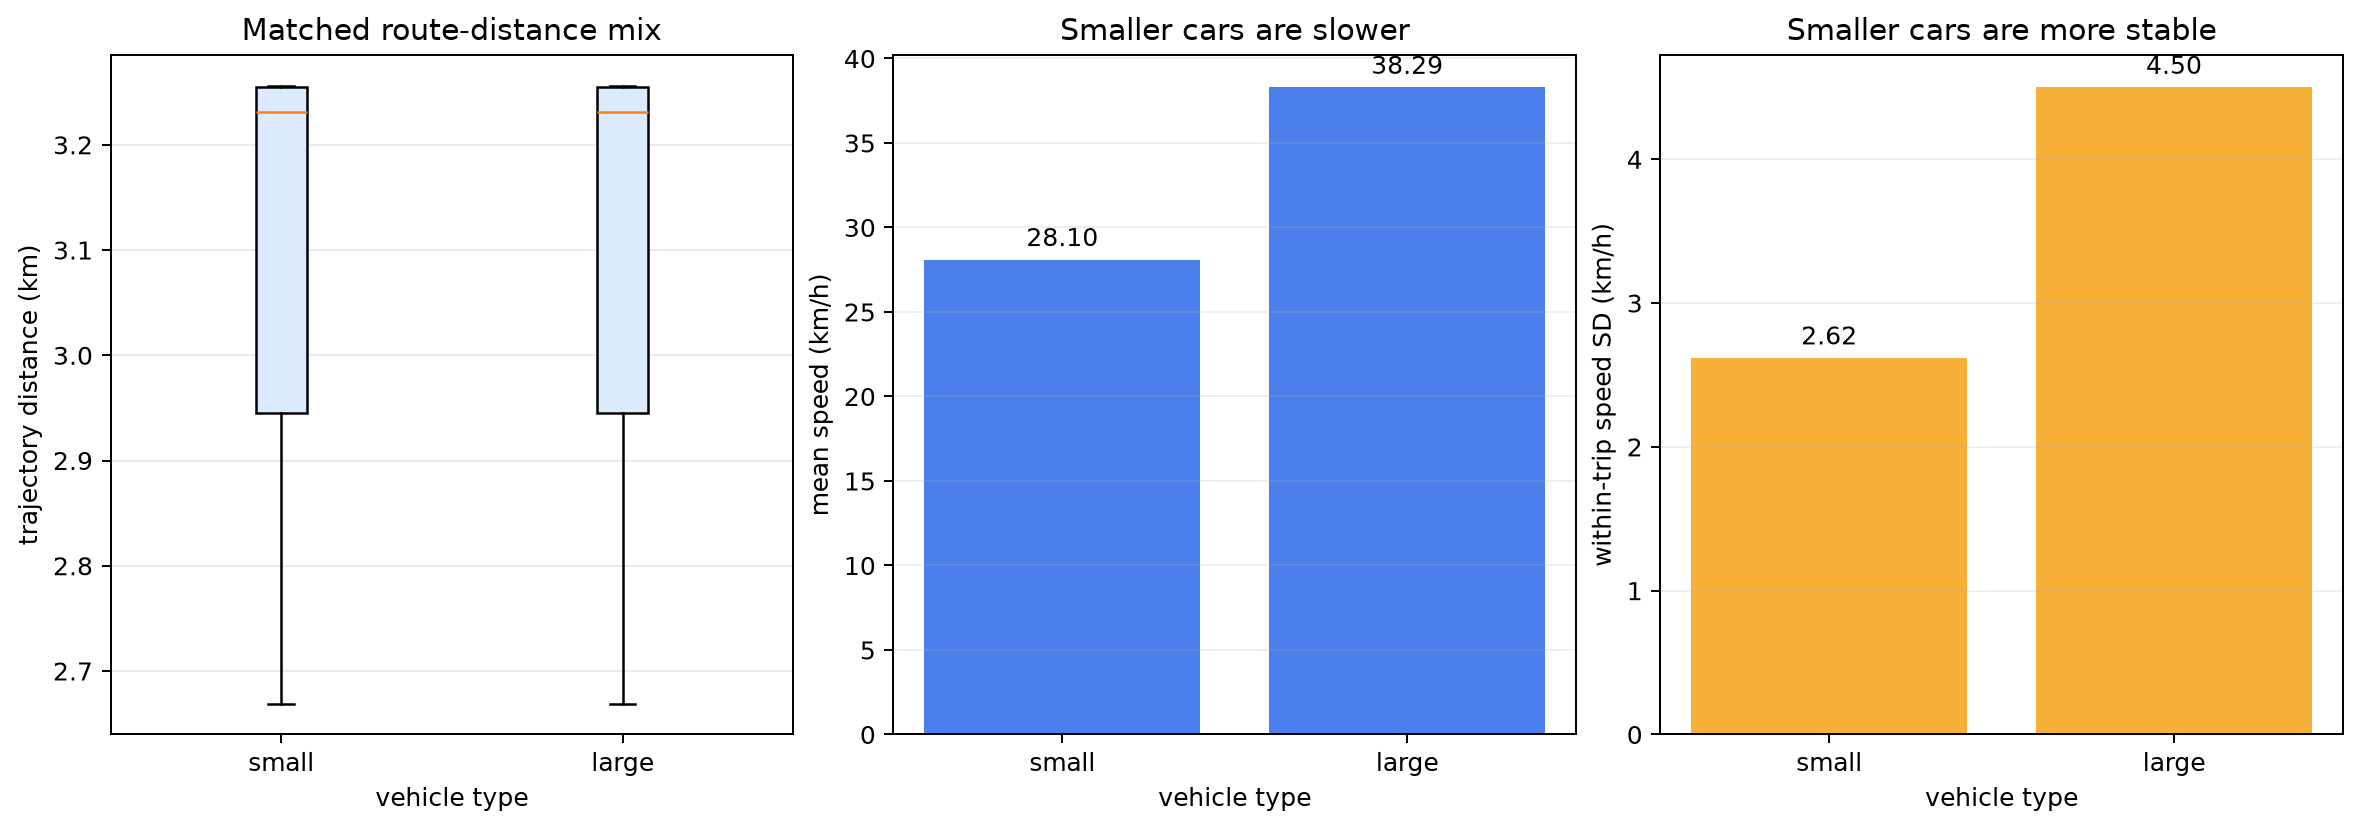

In [ ]:
ordinary=df[(~df.is_directness_exception)&df.vehicle_type.isin(['small','large'])];order=['small','large'];g=ordinary.groupby('vehicle_type').agg(distance=('trajectory_distance_km','mean'),speed=('mean_speed_kmh','mean'),speed_sd=('within_trip_speed_sd_kmh','mean')).reindex(order);print(g.round(2))
fig,ax=plt.subplots(1,3,figsize=(13,4.5),constrained_layout=True)
ax[0].boxplot([ordinary.loc[ordinary.vehicle_type.eq(k),'trajectory_distance_km'] for k in order],tick_labels=order,showfliers=False,patch_artist=True,boxprops={'facecolor':'#dbeafe'});ax[0].set(title='Matched route-distance mix',xlabel='vehicle type',ylabel='trajectory distance (km)');ax[0].grid(axis='y',alpha=.25)
for a,col,title,ylabel,color in [(ax[1],'speed','Smaller cars are slower','mean speed (km/h)','#2563eb'),(ax[2],'speed_sd','Smaller cars are more stable','within-trip speed SD (km/h)','#f59e0b')]:
    bars=a.bar(order,g[col],color=color,alpha=.82);a.bar_label(bars,fmt='%.2f',padding=3);a.set(title=title,xlabel='vehicle type',ylabel=ylabel);a.grid(axis='y',alpha=.2)
plt.show()
# Display the synchronized figure.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex18_insight_2",
  "insight": "Smaller cars maintain stabler trips but lower mean speed for same-distance trips compared to larger cars.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_2.png"
    ],
    "title": "Movement Efficiency and Stability: Insight 2",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "For comparable route-distance bands, how do smaller and larger cars differ in speed and stability?",
  "actionable_insight": "Show that small and large cars use the same route-distance mix, then compare mean speed and within-trip speed variability.",
  "code": "ordinary=df[(~df.is_directness_exception)&df.vehicle_type.isin(['small','large'])];order=['small','large'];g=ordinary.groupby('vehicle_type').agg(distance=('trajectory_distance_km','mean'),speed=('mean_speed_kmh','mean'),speed_sd=('within_trip_speed_sd_kmh','mean')).reindex(order);print(g.round(2))\nfig,ax=plt.subplots(1,3,figsize=(13,4.5),constrained_layout=True)\nax[0].boxplot([ordinary.loc[ordinary.vehicle_type.eq(k),'trajectory_distance_km'] for k in order],tick_labels=order,showfliers=False,patch_artist=True,boxprops={'facecolor':'#dbeafe'});ax[0].set(title='Matched route-distance mix',xlabel='vehicle type',ylabel='trajectory distance (km)');ax[0].grid(axis='y',alpha=.25)\nfor a,col,title,ylabel,color in [(ax[1],'speed','Smaller cars are slower','mean speed (km/h)','#2563eb'),(ax[2],'speed_sd','Smaller cars are more stable','within-trip speed SD (km/h)','#f59e0b')]:\n    bars=a.bar(order,g[col],color=color,alpha=.82);a.bar_label(bars,fmt='%.2f',padding=3);a.set(title=title,xlabel='vehicle type',ylabel=ylabel);a.grid(axis='y',alpha=.2)\nplt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vehicle_type",
    "matched_road_position",
    "trajectory_timestamp",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 3**: Are the most speed-stable trajectories always the most direct, or are there rare high-detour exceptions?

#### Analysis action

Compare directness distributions across speed-variability bands, then inspect route-directness ratios among the 20 most speed-stable trajectories and highlight the three flagged exceptions.

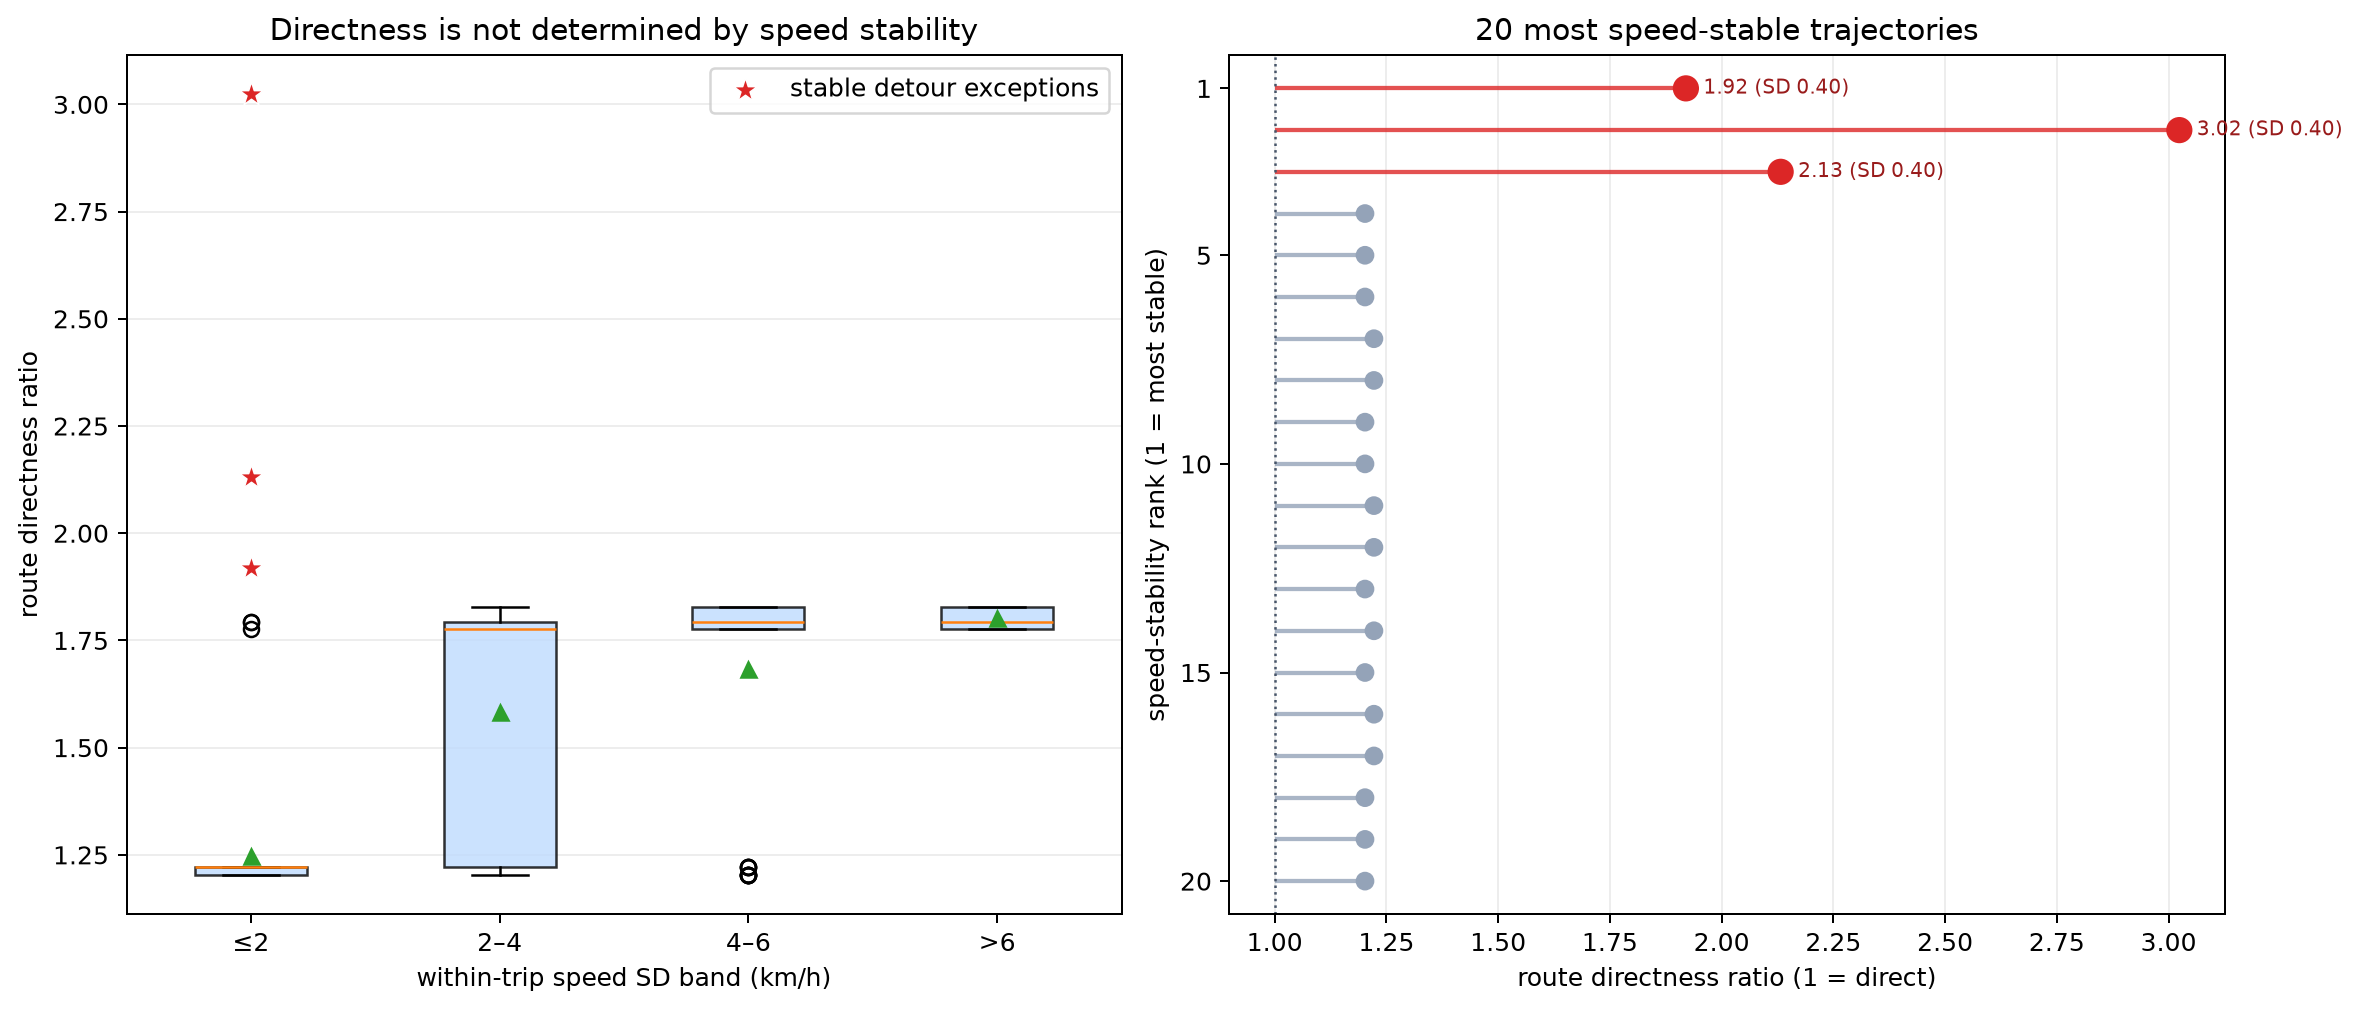

In [ ]:
stable=df.nsmallest(20,'within_trip_speed_sd_kmh').sort_values('within_trip_speed_sd_kmh').reset_index(drop=True);stable['stability_rank']=np.arange(1,len(stable)+1)
print(stable[['stability_rank','trajectory_id','vehicle_type','within_trip_speed_sd_kmh','route_directness_ratio','is_directness_exception']].to_string(index=False))
ordinary=df[~df.is_directness_exception].copy();ordinary['speed_variability_band']=pd.cut(ordinary.within_trip_speed_sd_kmh,[-np.inf,2,4,6,np.inf],labels=['≤2','2–4','4–6','>6'])
print('Ordinary directness by speed-variability band');print(ordinary.groupby('speed_variability_band',observed=False).route_directness_ratio.agg(['count','median','min','max']).round(2))
fig,ax=plt.subplots(1,2,figsize=(13,5.5),constrained_layout=True)
bands=['≤2','2–4','4–6','>6'];values=[ordinary.loc[ordinary.speed_variability_band.eq(x),'route_directness_ratio'] for x in bands]
bp=ax[0].boxplot(values,tick_labels=bands,patch_artist=True,showmeans=True);[box.set(facecolor='#bfdbfe',alpha=.8) for box in bp['boxes']]
exceptions=df[df.is_directness_exception].sort_values('route_directness_ratio');ax[0].scatter(np.full(len(exceptions),1),exceptions.route_directness_ratio,s=100,marker='*',color='#dc2626',edgecolor='white',linewidth=.6,zorder=5,label='stable detour exceptions')
ax[0].set(title='Directness is not determined by speed stability',xlabel='within-trip speed SD band (km/h)',ylabel='route directness ratio');ax[0].legend();ax[0].grid(axis='y',alpha=.22)
colors=np.where(stable.is_directness_exception,'#dc2626','#94a3b8');y=stable.stability_rank
ax[1].hlines(y,1,stable.route_directness_ratio,color=colors,linewidth=1.7,alpha=.8);ax[1].scatter(stable.route_directness_ratio,y,c=colors,s=np.where(stable.is_directness_exception,90,42),marker='o',zorder=3)
for _,r in stable[stable.is_directness_exception].iterrows(): ax[1].annotate(f"{r.route_directness_ratio:.2f} (SD {r.within_trip_speed_sd_kmh:.2f})",(r.route_directness_ratio,r.stability_rank),xytext=(7,0),textcoords='offset points',va='center',fontsize=8,color='#991b1b')
ax[1].axvline(1,color='#475569',linestyle=':',linewidth=1);ax[1].set_yticks([1,5,10,15,20]);ax[1].set_ylim(20.8,.2);ax[1].set(title='20 most speed-stable trajectories',xlabel='route directness ratio (1 = direct)',ylabel='speed-stability rank (1 = most stable)');ax[1].grid(axis='x',alpha=.22);plt.show()
# Display the synchronized figure.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex18_insight_3",
  "insight": "Speed-stabler trajectories are not definitely smaller route directness ration, there are few have largest route directness ratio",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_3.png"
    ],
    "title": "Movement Efficiency and Stability: Insight 3",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "Are the most speed-stable trajectories always the most direct, or are there rare high-detour exceptions?",
  "actionable_insight": "Compare directness distributions across speed-variability bands, then inspect route-directness ratios among the 20 most speed-stable trajectories and highlight the three flagged exceptions.",
  "code": "stable=df.nsmallest(20,'within_trip_speed_sd_kmh').sort_values('within_trip_speed_sd_kmh').reset_index(drop=True);stable['stability_rank']=np.arange(1,len(stable)+1)\nprint(stable[['stability_rank','trajectory_id','vehicle_type','within_trip_speed_sd_kmh','route_directness_ratio','is_directness_exception']].to_string(index=False))\nordinary=df[~df.is_directness_exception].copy();ordinary['speed_variability_band']=pd.cut(ordinary.within_trip_speed_sd_kmh,[-np.inf,2,4,6,np.inf],labels=['≤2','2–4','4–6','>6'])\nprint('Ordinary directness by speed-variability band');print(ordinary.groupby('speed_variability_band',observed=False).route_directness_ratio.agg(['count','median','min','max']).round(2))\nfig,ax=plt.subplots(1,2,figsize=(13,5.5),constrained_layout=True)\nbands=['≤2','2–4','4–6','>6'];values=[ordinary.loc[ordinary.speed_variability_band.eq(x),'route_directness_ratio'] for x in bands]\nbp=ax[0].boxplot(values,tick_labels=bands,patch_artist=True,showmeans=True);[box.set(facecolor='#bfdbfe',alpha=.8) for box in bp['boxes']]\nexceptions=df[df.is_directness_exception].sort_values('route_directness_ratio');ax[0].scatter(np.full(len(exceptions),1),exceptions.route_directness_ratio,s=100,marker='*',color='#dc2626',edgecolor='white',linewidth=.6,zorder=5,label='stable detour exceptions')\nax[0].set(title='Directness is not determined by speed stability',xlabel='within-trip speed SD band (km/h)',ylabel='route directness ratio');ax[0].legend();ax[0].grid(axis='y',alpha=.22)\ncolors=np.where(stable.is_directness_exception,'#dc2626','#94a3b8');y=stable.stability_rank\nax[1].hlines(y,1,stable.route_directness_ratio,color=colors,linewidth=1.7,alpha=.8);ax[1].scatter(stable.route_directness_ratio,y,c=colors,s=np.where(stable.is_directness_exception,90,42),marker='o',zorder=3)\nfor _,r in stable[stable.is_directness_exception].iterrows(): ax[1].annotate(f\"{r.route_directness_ratio:.2f} (SD {r.within_trip_speed_sd_kmh:.2f})\",(r.route_directness_ratio,r.stability_rank),xytext=(7,0),textcoords='offset points',va='center',fontsize=8,color='#991b1b')\nax[1].axvline(1,color='#475569',linestyle=':',linewidth=1);ax[1].set_yticks([1,5,10,15,20]);ax[1].set_ylim(20.8,.2);ax[1].set(title='20 most speed-stable trajectories',xlabel='route directness ratio (1 = direct)',ylabel='speed-stability rank (1 = most stable)');ax[1].grid(axis='x',alpha=.22);plt.show()",
  "insight_type": "exception_deviation",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "matched_road_position",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 18)

Trips during peak periods show greater variation in travel time and speed than trips during off-peak periods. Smaller cars maintain stabler trips but lower mean speed for same-distance trips compared to larger cars. Speed-stabler trajectories are not definitely smaller route directness ration, there are few have largest route directness ratio